# ML1 - GridSearch avec DecisionTreeRegression, RandomForestRegressor

Ce notebook fait suite au notebook ML1_Pipeline_Model et se concentre sur :
1. L'utilisation de DecisionTreeRegressor et RandomForestRegressor ou d'autres
2. L'optimisation des hyperparamètres avec GridSearchCV
3. La validation croisée (cross-validation)

## 1. Import des bibliothèques

In [1]:
# Les libraries nécessaires
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_squared_error

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.linear_model import LassoCV

from sklearn.feature_selection import SelectFromModel

from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.tree import DecisionTreeRegressor

## 2. Chargement et préparation des données avec le PipeLine.

Nous reprenons les mêmes étapes de préparation que dans le notebook précédent.

In [2]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')

df['Latitude'] = df['Latitude'].map(lambda x:float(x))
df['Longitude'] = df['Longitude'].map(lambda x:float(x))
df['adr_secteur'] = df['adr_secteur'].map(lambda x:str(x))
df['taxon'] = df['genre_bota']+ ' ' + df['espece'].fillna('sp.')

df = df.drop(['collectivite', 'portarbre', 'genre_bota', 'espece'], axis=1)
annee = df.pop('anneedeplantation')

X_train, X_test, y_train, y_test = train_test_split(df, annee, random_state=28)

cat_var = df.select_dtypes(include=str).columns.tolist()
num_var = df.select_dtypes(exclude=str).columns.tolist()

transformer = ColumnTransformer([
    ("Numerical standardization", StandardScaler(), num_var),
     ("Categorical standardization", OneHotEncoder(handle_unknown='ignore'), cat_var)
])
#ridge needs sparce = False
X_prepared = transformer.fit_transform(X_train)
X_test_prepared = transformer.transform(X_test)


## 3. Cross-validation initiale

Avant d'optimiser les hyperparamètres, évaluons un modèle avec les paramètres par défaut en utilisant la validation croisée.

In [ ]:
# Validation croisée initiale sans optimisation des hyperparamètres
# On peut aussi imprimer les scores MSE ou MAE de chaque cross-validation.

model_0 = RandomForestRegressor(max_depth=20, random_state=28)
model_0.fit(X_prepared, y_train)

y_pred_train0 = model_0.predict(X_prepared)
mse_train0 = mean_squared_error(y_train, y_pred_train0)
print('Train MSE: {0}'.format(mse_train0))

# predict y values for testing data set
y_pred_test0 = model_0.predict(X_test_prepared)
mse_test0 = mean_squared_error(y_test, y_pred_test0)
print('Test MSE: {0}'.format(mse_test0))

#Cross-validation
cv_scores0 = cross_val_score(model_0, X_prepared, y_train, cv = 5, scoring='neg_mean_squared_error')
print('CV MSE:',np.mean(-cv_scores0))
print(-cv_scores0)

Train MSE: 12.895378576445534
Test MSE: 36.18165345538679
CV MSE: 40.94837832810311
[42.54753687 37.85549949 39.76632024 47.12447446 37.44806058]


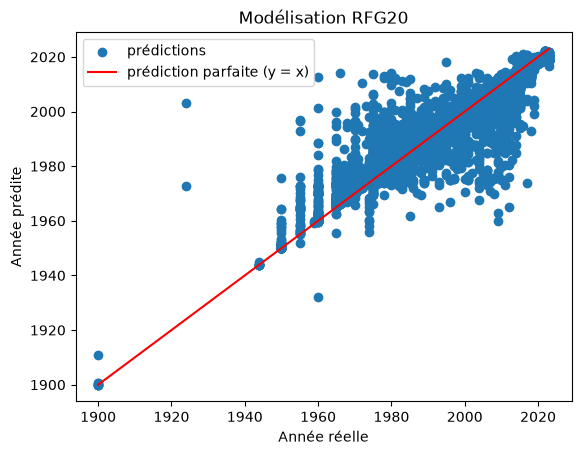

In [7]:
# Visualisation des prédictions.
plt.scatter(y_test, y_pred_test0, label='prédictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
plt.legend()
plt.xlabel('Année réelle')
plt.ylabel('Année prédite')
plt.title('Modélisation RFG20')
plt.show()

## 4. 🌳 Modélisation avec GridSearchCV

Choisissons deux models de machine learning.

Évaluer les modèles avec optimisation (en testant différentes valeurs des hyperparamètres).
Optimisez les modèles comme vous le souhaitez, par exemple pour l'arbre des des decisions et forêt aléatoire :

### 🔍 Hyperparamètres testés
- `max_depth`: profondeur maximale des arbres [3, 4, 5, 10]
- `min_samples_leaf`: nombre minimum d'échantillons requis dans une feuille [0.1, 0.05]
- `n_estimators` (pour la forêt aléatoire uniquement) : nombre d'arbres dans la foret [50, 100, 200]

Utilisons GridSearchCV pour automatiser la recherche des meilleurs hyperparamètres.

In [ ]:
#Optimisation des hyperparamètres avec GridSearchCV et on peut imprimer les score MSE ou MAE de chaque cross-validation.
#pipeline = Pipeline([
#        ("classifier", RandomForestRegressor())
#])


#Je fais une RandomSearch pour explorer, et gridsearch quand j'aurais précisé mes hypothèses.
param_distributions = {
    'max_depth': [10, 20, 30, None],
    'min_samples_leaf': [1, 2, 5, 10],
    'n_estimators': [50, 100, 200]
}

forest_grid = RandomizedSearchCV(RandomForestRegressor(random_state=28), param_distributions, n_iter=30, cv=5, scoring='neg_mean_squared_error', random_state=28, n_jobs=-1)
forest_grid.fit(X_prepared, y_train)

In [5]:
forest_grid.best_params_

{'n_estimators': 50, 'min_samples_leaf': 0.05, 'max_depth': 10}

## 5. Évaluation finale sur le set de test

In [6]:
# Code pour l'evaluation du meilleur modèle sur le set de test.
forresults = pd.DataFrame(forest_grid.cv_results_)

y_pred = forest_grid.predict(X_test_prepared)
mse1 = mean_squared_error(y_test, y_pred)
best_cv_mse1 = -forest_grid.best_score_

print('train MSE:',np.mean(-cv_scores))
print('test MSE model 0: {0}'.format(mse_test0))
print('train MSE model RS', best_cv_mse1)
print('test MSE: model RS', mse1)

train MSE: 135.2190564023791
test MSE model 0: 138.2883223596487
train MSE model RS 180.71491527048244
test MSE: model RS 179.48773174920083


## 6. Visualisation des prédictions
Un seul model suffira.

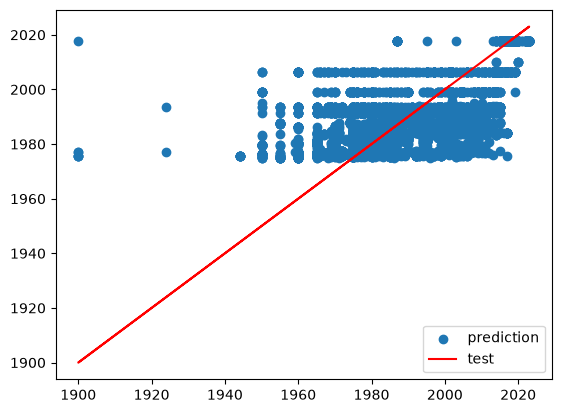

In [7]:
# Visualisation des prédictions.
plt.scatter(y_test, y_pred)
plt.plot(y_test,y_test, 'r')
plt.legend(['prediction','test'])

## 7. [OPTIONNEL] Importance des features

En utilisant la forêt aléatoire, comment peut-on savoir quelles sont les features les plus importantes ?

In [8]:
# Code, et à votre avis, comment etait calculé l'importance des features dans la forêt aléatoire ?
# Extract feature importances
bm = forest_grid.best_estimator_
importances = bm.feature_importances_

feature_names = transformer.get_feature_names_out()
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Rank features by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df[:10])

# Select top N features (example selecting top 10 features)
top_features = feature_importance_df['Feature'][:10].values


                                               Feature  Importance
21   Categorical standardization__stadededeveloppem...    0.651776
24   Categorical standardization__stadededeveloppem...    0.092742
25   Categorical standardization__hauteurarbre_Moin...    0.082925
40         Categorical standardization__typenature_nan    0.078431
1                 Numerical standardization__Longitude    0.070082
258  Categorical standardization__taxon_Platanus ac...    0.012552
4    Categorical standardization__sous_categorie_ES...    0.002853
0                  Numerical standardization__Latitude    0.002445
27   Categorical standardization__hauteurarbre_de 1...    0.001811
7    Categorical standardization__sous_categorie_de...    0.001592


Typiquement, on pourrait envisager de faire une backward elimination sur l'importance des features pour sélectionner le meilleur sous ensemble de features, mais cela peut-etre long si on a beaucoup de features et un modèle un peu long à entrainer comme c'est le cas ici. À la place on peut utiliser une regression avec regularisation lasso pour éliminer des features, avant de ré-entrainer une RandomForest sur les features sélectionnées. Créez un pipeline avec `LassoCV` comme selector et une RandomForest avec les meilleurs hyper-paramètres trouvés par la grid search en model. Évaluez sur le set de test.


In [9]:
# Code
#forest_grid.best_params_
selector = SelectFromModel(LassoCV(alphas=[0.01, 0.1,1,10, 100] ,cv=5, random_state=28, max_iter=10000))
regressor = RandomForestRegressor(**forest_grid.best_params_, random_state=28)

full_pipeline = Pipeline([
    ("selector", selector), 
    ("regressor", regressor)])

full_pipeline.fit(X_prepared, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selector', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,407
,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",LassoCV(alpha...ndom_state=28)
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",None
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1
,"max_features max_features: int, callable, default=NoneThe maximum number of features to select.- If an integer, then it specifies the maximum number of features to allow.- If a callable, then it specifies how to calculate the maximum number of features allowed. The callable will receive `X` as input: `max_features(X)`.- If `None`, then all features are kept.To only select based on ``max_features``, set ``threshold=-np.inf``... versionadded:: 0.20.. versionchanged:: 1.1 `max_features` accepts a callable.",None


In [10]:
y_pred = full_pipeline.predict(X_test_prepared)
mse2 = mean_squared_error(y_test, y_pred)

print('train MSE M0:',np.mean(-cv_scores))
print('test MSE M0: {0}'.format(mse_test0))
print('test MSE: MRS', mse1)
print('test MSE MLS : ', mse2)

train MSE M0: 135.2190564023791
test MSE M0: 138.2883223596487
test MSE: MRS 179.48773174920083
test MSE MLS :  180.3777282850627


In [11]:
#Scores with drops
# train MSE M0: 135.87798693274013
# test MSE M0: 137.25592283372134
# test MSE: MRS 179.2222285613482
# test MSE MLS :  178.9716607863057

In [16]:
N = 20

bm = full_pipeline[1]
importances = bm.feature_importances_
length = range(0,len(importances))

feature_names = transformer.get_feature_names_out()
feature_importance_df = pd.DataFrame({'Feature': feature_names[full_pipeline['selector'].get_support()], 'Importance': importances})

# Rank features by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df[:N])

# Select top N features (example selecting top 10 features)
top_features = feature_importance_df['Feature'][:N].values

                                              Feature  Importance
15  Categorical standardization__stadededeveloppem...    0.655032
17  Categorical standardization__stadededeveloppem...    0.102136
18  Categorical standardization__hauteurarbre_Moin...    0.083163
28        Categorical standardization__typenature_nan    0.071416
1                Numerical standardization__Longitude    0.065613
79  Categorical standardization__taxon_Platanus ac...    0.008880
0                 Numerical standardization__Latitude    0.003119
20  Categorical standardization__hauteurarbre_de 1...    0.002577
19  Categorical standardization__hauteurarbre_Plus...    0.002535
4   Categorical standardization__sous_categorie_ES...    0.002155
7   Categorical standardization__sous_categorie_de...    0.002143
24  Categorical standardization__structure_Ville d...    0.000869
23  Categorical standardization__structure_Métropo...    0.000200
27      Categorical standardization__typenature_Libre    0.000160
8   Catego

## 8. [OPTIONNEL] Comparez différents modèles de regression

Comparez plus de modèles de régression entre eux (par exemple en plus de la régression linéaire, des arbres de décision et des forets, le `GradientBoostingRegressor`, et le plus récent `TabICLRegressor` si vous avez le temps ( https://github.com/soda-inria/tabicl )), en faisant une recherche d'hyperparamètre adéquate à chaque modèle :

In [13]:
#Code, cherchez des examples pour trouver quels sont les hyper-parametres importants pour chaque modèle

Choisissez le modèle qui marche le mieux et ses meilleurs hyper-paramètres, sélectionnez le meilleur sous-ensemble de features pour ce modèle, et enfin refaites une dernière grid-search sur les hyper-paramètres de votre modèle avec les features retenues, pour obtenir votre modèle final. Évaluez sur le test set.

In [14]:
#Code

## Conclusion